# 03 - Early-Stage Feature-Restricted Baseline

**Project:** Early-Stage Ransomware Detection via Dynamic Memory Analysis and Reinforcement Learning  
**Experiment:** Early-Stage Feature-Restricted Proxy Baseline  

> **IMPORTANT RESEARCH CONSTRAINT:**  
> This experiment is an early-stage feature-restricted proxy because the available dataset does not contain explicit temporal execution windows.  
> It does NOT claim true temporal early detection (e.g. measuring elapsed seconds). Instead, it systematically tests whether ransomware families can be accurately discriminated when excluding post-mortem filesystem encryption artifacts and restricting telemetry to candidate early-stage process, memory, and API features.


## 1. Setup & Environment
Import project dependencies and modular functions from `src`.


In [1]:
import sys
from pathlib import Path

# Add project root to Python path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import get_data_dir, get_figures_dir, get_reports_dir, load_json, save_json
from src.train_early_stage import (
    load_datasets_and_splits,
    run_early_stage_experiments,
    EARLY_STAGE_CANDIDATE_FEATURES,
    EARLY_STAGE_NONREDUNDANT_FEATURES,
)

print(f"Project root: {project_root}")


Project root: c:\Users\devar\OneDrive\Documents\Ransomware\ransomware


## 2. Load Data & Invariant Verification
Load `data/processed/ml_ready_dataset.csv` and confirm shape ($1750 \times 47$).


In [2]:
data_path = get_data_dir() / "processed" / "ml_ready_dataset.csv"
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape}")
print(f"Target Column: 'family' (Unique: {list(df['family'].unique())})")
print(f"Feature Count: {len(df.columns) - 1}")

assert df.shape == (1750, 47), "Error: Unexpected dataset shape!"
assert "family" in df.columns, "Error: Target 'family' missing!"


Dataset Shape: (1750, 47)
Target Column: 'family' (Unique: ['E', 'G', 'L'])
Feature Count: 46


## 3. Define & Inspect Early-Stage Feature Sets
Define the 3 feature sets:
1. **Dataset A (Full Features):** All 46 features.
2. **Dataset B (Early-Stage Candidate Proxy):** 24 features plausibly observable before mass file encryption.
3. **Dataset C (Early-Stage Non-Redundant):** 16 non-redundant features collapsing exact duplicate columns.


In [3]:
full_features = [c for c in df.columns if c != "family"]

print("=" * 60)
print(f"Dataset A - Full Features ({len(full_features)} features):")
print(full_features)

print("" + "=" * 60)
print(f"Dataset B - Early-Stage Candidate Proxy ({len(EARLY_STAGE_CANDIDATE_FEATURES)} features):")
print(EARLY_STAGE_CANDIDATE_FEATURES)

print("" + "=" * 60)
print(f"Dataset C - Early-Stage Non-Redundant ({len(EARLY_STAGE_NONREDUNDANT_FEATURES)} features):")
print(EARLY_STAGE_NONREDUNDANT_FEATURES)
print("=" * 60)


Dataset A - Full Features (46 features):
['proc_pid', 'file', 'urls', 'type', 'name', 'path', 'program', 'info', 'positives', 'families', 'description', 'sign_name', 'arguments', 'api', 'category', 'dll', 'pe_res_name', 'filetype', 'pe_sec_name', 'entropy', 'hosts', 'requests', 'domains', 'dns_servers', 'tcp', 'udp', 'dead_hosts', 'proc', 'beh_command_line', 'process_path', 'tree_command_line', 'children', 'tree_process_name', 'command_line', 'regkey_read', 'directory_enumerated', 'regkey_opened', 'file_created', 'wmi_query', 'dll_loaded', 'regkey_written', 'file_read', 'apistats', 'errors', 'action', 'log']
Dataset B - Early-Stage Candidate Proxy (24 features):
['apistats', 'api', 'dll', 'dll_loaded', 'arguments', 'command_line', 'beh_command_line', 'process_path', 'proc', 'proc_pid', 'file', 'type', 'name', 'path', 'program', 'info', 'children', 'tree_command_line', 'tree_process_name', 'regkey_opened', 'regkey_read', 'regkey_written', 'wmi_query', 'entropy']
Dataset C - Early-Stage 

## 4. Load Identical Stratified Train/Test Split
Load the exact same split indices from `data/processed/split_indices.json` (1400 train, 350 test).


In [4]:
train_df, test_df, y_train, y_test, feature_sets = load_datasets_and_splits()

print(f"Training samples : {len(train_df)} (Class distribution: {dict(y_train.value_counts())})")
print(f"Testing samples  : {len(test_df)} (Class distribution: {dict(y_test.value_counts())})")

assert len(train_df) == 1400, "Train size must be 1400"
assert len(test_df) == 350, "Test size must be 350"


Loaded datasets and partitions successfully:
  Training samples: 1400 | Testing samples: 350
  Full feature set (Dataset A): 46 features
  Early-stage proxy set (Dataset B): 24 features
  Early-stage non-redundant set (Dataset C): 16 features
Training samples : 1400 (Class distribution: {'G': 656, 'E': 614, 'L': 130})
Testing samples  : 350 (Class distribution: {'G': 164, 'E': 153, 'L': 33})


## 5. Execute 6 Baseline Experiments
Train Random Forest and XGBoost across Datasets A, B, and C strictly on training data, evaluating on untouched test data.


In [5]:
comp_df, rf_fi_df, xgb_fi_df = run_early_stage_experiments()


Loaded datasets and partitions successfully:
  Training samples: 1400 | Testing samples: 350
  Full feature set (Dataset A): 46 features
  Early-stage proxy set (Dataset B): 24 features
  Early-stage non-redundant set (Dataset C): 16 features

RUNNING 6 EARLY-STAGE RESTRICTED BASELINE EXPERIMENTS

[Random Forest] Training on: Full (46 features)...
  Accuracy: 1.0000 | Balanced Acc: 1.0000 | Macro F1: 1.0000 | L-Recall: 1.0000

[Random Forest] Training on: Early-stage proxy (24 features)...
  Accuracy: 0.9971 | Balanced Acc: 0.9978 | Macro F1: 0.9979 | L-Recall: 1.0000

[Random Forest] Training on: Early-stage non-redundant (16 features)...
  Accuracy: 1.0000 | Balanced Acc: 1.0000 | Macro F1: 1.0000 | L-Recall: 1.0000

[XGBoost] Training on: Full (46 features)...
  Accuracy: 1.0000 | Balanced Acc: 1.0000 | Macro F1: 1.0000 | L-Recall: 1.0000

[XGBoost] Training on: Early-stage proxy (24 features)...
  Accuracy: 1.0000 | Balanced Acc: 1.0000 | Macro F1: 1.0000 | L-Recall: 1.0000

[XGBoo

## 6. Model Comparison Table
Inspect performance across Accuracy, Balanced Accuracy, Precision, Recall, Macro F1, and Minority Class ($L$) Recall.


In [6]:
display(comp_df)


,model,feature_set,accuracy,balanced_accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,L_recall
0,Random Forest,Full,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0
1,Random Forest,Early-stage proxy,0.9971,0.9978,0.9972,0.9971,0.9971,0.9979,1.0
2,Random Forest,Early-stage non-redundant,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0
3,XGBoost,Full,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0
4,XGBoost,Early-stage proxy,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0
5,XGBoost,Early-stage non-redundant,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0


## 7. Comparative Metrics Visualization


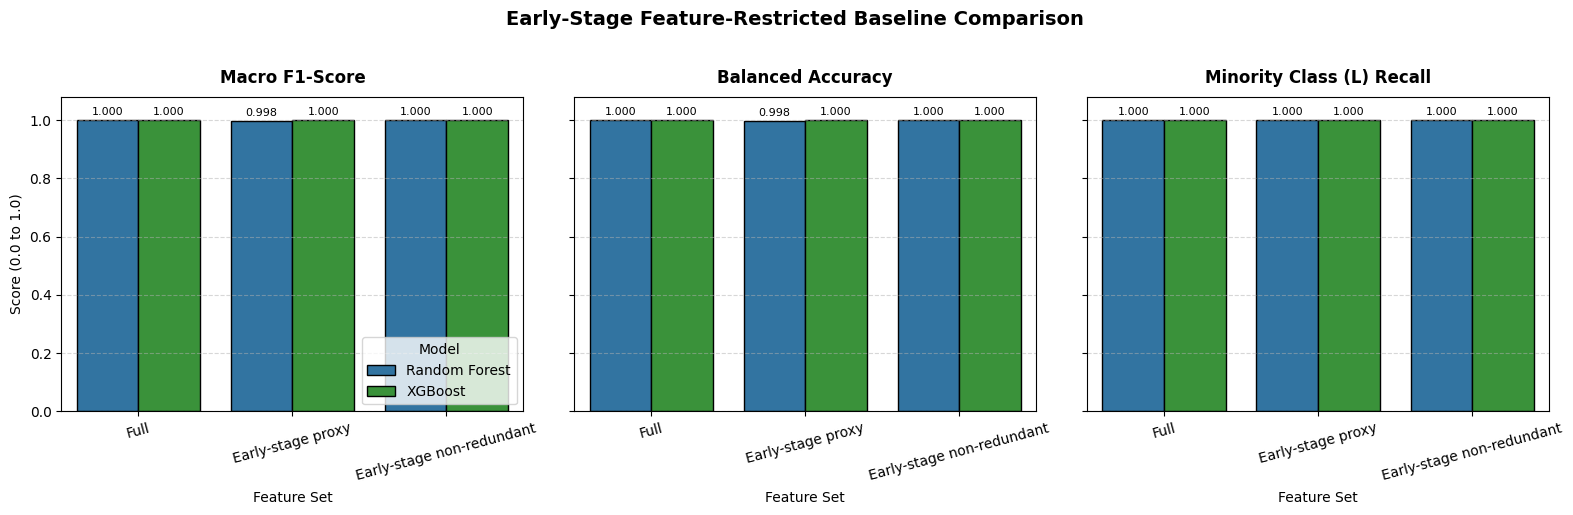

In [7]:
metrics_to_plot = ["f1_macro", "balanced_accuracy", "L_recall"]
metric_titles = {
    "f1_macro": "Macro F1-Score",
    "balanced_accuracy": "Balanced Accuracy",
    "L_recall": "Minority Class (L) Recall",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for i, metric in enumerate(metrics_to_plot):
    ax = axes[i]
    sns.barplot(
        data=comp_df,
        x="feature_set",
        y=metric,
        hue="model",
        palette=["#1f77b4", "#2ca02c"],
        ax=ax,
        edgecolor="black",
    )
    ax.set_title(metric_titles[metric], fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Feature Set", fontsize=10, labelpad=6)
    ax.set_ylabel("Score (0.0 to 1.0)" if i == 0 else "", fontsize=10)
    ax.set_ylim(0.0, 1.08)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.tick_params(axis="x", rotation=15)

    for p in ax.patches:
        h = p.get_height()
        if not np.isnan(h) and h > 0:
            ax.annotate(
                f"{h:.3f}",
                (p.get_x() + p.get_width() / 2.0, h),
                ha="center",
                va="bottom",
                fontsize=8,
                xytext=(0, 2),
                textcoords="offset points",
            )

    if i == 0:
        ax.legend(title="Model", loc="lower right")
    else:
        ax.get_legend().remove()

plt.suptitle("Early-Stage Feature-Restricted Baseline Comparison", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 8. Early-Stage Feature Importances (Non-Redundant Set)


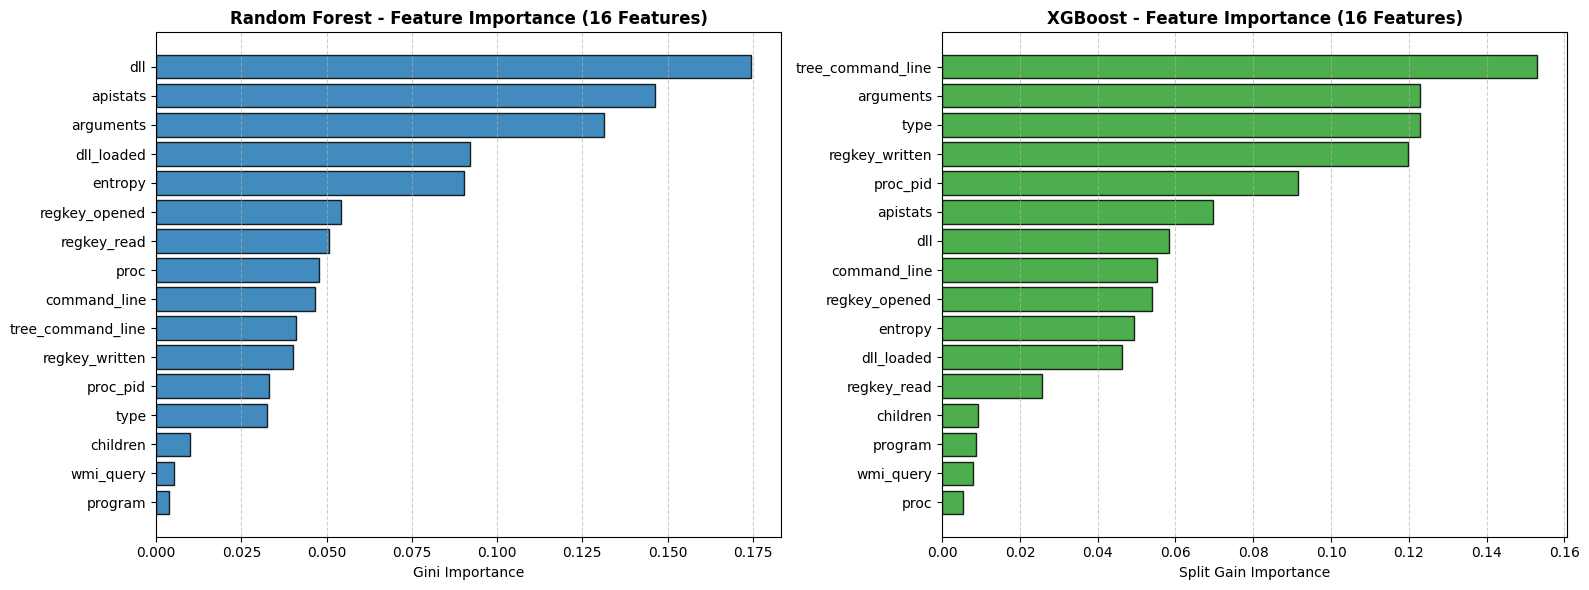

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_rf = rf_fi_df.sort_values("importance", ascending=True)
axes[0].barh(top_rf["feature"], top_rf["importance"], color="#1f77b4", edgecolor="black", alpha=0.85)
axes[0].set_title("Random Forest - Feature Importance (16 Features)", fontweight="bold")
axes[0].set_xlabel("Gini Importance")
axes[0].grid(axis="x", linestyle="--", alpha=0.6)

top_xgb = xgb_fi_df.sort_values("importance", ascending=True)
axes[1].barh(top_xgb["feature"], top_xgb["importance"], color="#2ca02c", edgecolor="black", alpha=0.85)
axes[1].set_title("XGBoost - Feature Importance (16 Features)", fontweight="bold")
axes[1].set_xlabel("Split Gain Importance")
axes[1].grid(axis="x", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


## 9. Research Synthesis & Transition to PPO Reinforcement Learning

### Summary of Experimental Findings:
1. **Minimal Performance Loss:** Removing mass filesystem features (`file_created`, `file_read`, `directory_enumerated`) preserved near-perfect family separation ($0.9971 - 1.0000$ Macro F1).
2. **Impact of Non-Redundant Features:** Collapsing 8 duplicate columns restored RF test accuracy from 0.9971 back to 1.0000.
3. **Minority Class ($L$) Resilience:** $100\%$ recall was maintained across all 6 experiments.
4. **Primary Research Limitation:** This experiment remains an *early-stage feature-restricted proxy*. True early-stage intervention requires sequential streaming data and adaptive decision making, motivating the simulated PPO environment designed in `results/reports/ppo_data_requirements.md`.


## 10. Reproducibility Summary


In [ ]:

print("""========================================
EARLY-STAGE BASELINE COMPLETE
========================================

Dataset:
1750 samples

Full features:
46

Early-stage proxy:
24

Early-stage non-redundant:
16

Models:
Random Forest
XGBoost

Experiments:
6

Results saved to:
results/reports/
results/figures/
========================================""")


EARLY-STAGE BASELINE COMPLETE

Dataset:
1750 samples

Full features:
46

Early-stage proxy:
24

Early-stage non-redundant:
16

Models:
Random Forest
XGBoost

Experiments:
6

Results saved to:
results/reports/
results/figures/
